#### ***Tool Calling***
- ***Tools are external functions, APIs, databases, or services that an AI agent can actively invoke.***

- ***They allow the agent to perform actions beyond text generation such as searching the web, executing code, or calculating complex math.***

#### ***Common Searching Tools***
- Web search tool : searches for current information.
- Calculator tool : performs accurate mathematical calculations.
- Database tool : reads or writes data.
- RAG retriever tool : searches documents or vector    databases.
- Python tool : executes code and analyzes data.
- Email tool : reads, drafts, or sends emails.
- Calendar tool : checks availability or creates events.
- API tool : communicates with services such as weather, finance, CRM, or payment systems.
- Custom business tools : create tickets, check inventory, generate reports, or update customer records.


In [1]:
import warnings 
warnings.filterwarnings("ignore")

from langgraph.graph import StateGraph,START,END
from typing import TypedDict,Annotated
from langchain_core.messages import BaseMessage,HumanMessage
from langchain_groq import ChatGroq
from langchain_google_genai import ChatGoogleGenerativeAI
from langgraph.graph.message import add_messages
from langgraph.prebuilt import ToolNode,tools_condition
from langchain_tavily import TavilySearch
from langchain_core.tools import tool 
from typing import Any 

from dotenv import load_dotenv
load_dotenv()

import requests
import math
import os 

d:\AIML_Engineer\AIML_Stack\Agentic_AI\venv\Lib\site-packages\langgraph\checkpoint\base\__init__.py:18: LangChainPendingDeprecationWarning: The default value of `allowed_objects` will change in a future version. Pass an explicit value (e.g., allowed_objects='messages' or allowed_objects='core') to suppress this warning.
  from langgraph.checkpoint.serde.jsonplus import JsonPlusSerializer


In [2]:
# Define Our Model
llm = ChatGroq(
    model="openai/gpt-oss-120b",
    temperature=0
)

LLM =  ChatGoogleGenerativeAI(
    model="gemini-2.5-flash",
    temperature=0.3
)

In [3]:
# Define Our Tool 
search_tool = TavilySearch(
    max_results = 3,
    topic="general",
    search_depth="advanced"
)

In [4]:
@tool
def calculator(expression: str) -> str:
    """
    Useful for performing simple mathematical calculations.

    Input should be a valid mathematical expression.
    Examples:
    - 2 + 2
    - math.sqrt(16)
    - 10 * 5
    """
    try:
        allowed = {
            "math": math,
            "abs": abs,
            "round": round,
            "min": min,
            "max": max,
            "sum": sum,
        }

        result = eval(expression, {"__builtins__": {}}, allowed)
        return str(result)

    except Exception as e:
        return f"Calculation error: {e}"

In [5]:
@tool
def get_stock_price(symbol: str) -> dict:
    """
    Fetch the latest stock price for a given stock symbol.
    Example: AAPL, TSLA, MSFT
    """
    try:
        url = f"https://www.alphavantage.co/query?function=GLOBAL_QUOTE&symbol={symbol}&apikey={os.getenv('ALPHA_VANTAGE_API_KEY')}"
        response = requests.get(url)
        return response.json()
    except Exception as e:
        return {"error": str(e)}

In [6]:
@tool
def get_current_weather(location: str) -> str:
    """
    Get the current weather for a city.
    Example: Delhi, London, New York
    """
    try:
        api_key = os.getenv("OPENWEATHER_API_KEY")

        url = "https://api.openweathermap.org/data/2.5/weather"

        params = {
            "q": location,
            "appid": api_key,
            "units": "metric"
        }

        data = requests.get(url, params=params).json()

        if data.get("cod") != 200:
            return f"Weather not found for {location}."

        weather = data["weather"][0]["description"]
        temp = data["main"]["temp"]
        humidity = data["main"]["humidity"]

        return (
            f"Weather in {location}: {weather.title()}, "
            f"Temperature: {temp}°C, Humidity: {humidity}%."
        )

    except Exception as e:
        return f"Error: {e}"

In [7]:
# Tool List 
tools = [search_tool,calculator, get_stock_price,get_current_weather]

# LLM To Aware (bind our tool)
llm_with_tools = llm.bind_tools(tools)

In [8]:
# Define State 
class Chat_State(TypedDict):
    messages:Annotated[list[BaseMessage],add_messages]


# graph nodes
def chat_node(state: Chat_State):
    """LLM node that may answer or request a tool call."""
    messages = state['messages']
    response = llm_with_tools.invoke(messages)
    return {"messages": [response]}

tool_node = ToolNode(tools)  # Executes tool calls

In [9]:
# graph structure
graph = StateGraph(Chat_State)
graph.add_node("chat_node", chat_node)
graph.add_node("tools", tool_node)


graph.add_edge(START, "chat_node")
graph.add_conditional_edges("chat_node", tools_condition)
graph.add_edge("tools", "chat_node") 

chatbot = graph.compile()

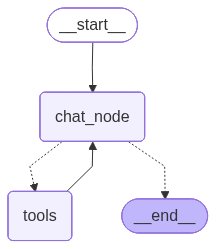

In [10]:
from IPython.display import Image
Image(chatbot.get_graph().draw_mermaid_png())

In [11]:
# Regular chat
out = chatbot.invoke({"messages": [HumanMessage(content="Hello..!")]})

print(out["messages"][-1].content)

Hello! 👋 How can I assist you today?


In [12]:
# Chat requiring tool
out = chatbot.invoke({"messages": [HumanMessage(content="What is 8989898*90909090+5404040?")]})
print(out["messages"][-1].content)

The result of the calculation \(8989898 \times 90909090 + 5404040\) is **817,263,451,776,860**.


In [15]:
# Chat requiring tool
out = chatbot.invoke({"messages": [HumanMessage(content="what is the current stock market analysis in 2026")]})
print(out["messages"][-1].content)

**2026 Stock‑Market Landscape – A Quick‑Turn‑Around View (as of July 2026)**  

Below is a synthesis of the most recent market‑outlook research from three leading institutions (T. Rowe Price, J.P. Morgan, and State Street) together with a few concrete data points that have emerged in the first half of 2026.  All statements are tied to the source material that was retrieved in the search.

---

## 1.  Macro‑Economic Backdrop  

| Factor | What the analysts see | Why it matters for equities |
|--------|----------------------|----------------------------|
| **Monetary policy** | The Fed is in the “final stretch” of rate normalization – a modest **insurance cut** is expected later in 2026, while the Bank of England may still be tightening. Central‑bank moves are diverging across regions, creating “opportunity and risk across asset classes.” – *J.P. Morgan*【2†L13-L19】 | A slower‑rising rate environment supports risk assets, but any surprise tightening could spark volatility, especially in r

In [16]:
# Chat requiring tool
out = chatbot.invoke({"messages": [HumanMessage(content="what is the current weather report of mainpuri and agra")]})
print(out["messages"][-1].content)

**Current Weather (as of 2026‑07‑05)**  

| City      | Condition | Temperature | Humidity |
|-----------|-----------|-------------|----------|
| Mainpuri  | Light rain | 39.7 °C | 32 % |
| Agra      | Light rain | 40.4 °C | 29 % |

Both locations are experiencing light rain with very high temperatures near 40 °C and relatively low humidity. Stay hydrated and consider indoor activities if you’re planning to be outdoors.


In [19]:
# Chat requiring tool
out = chatbot.invoke({"messages": [HumanMessage(content="First find out the stock price of Apple using get stock price tool then use the calculator tool to find out how much will it take to purchase 50 shares?")]})
print(out["messages"][-1].content)

The current price of Apple (AAPL) is **$308.63** per share.  

To buy **50 shares**:

\[
308.63 \times 50 = \boxed{\$15,431.50}
\]


In [20]:
# Chat requiring tool
out = chatbot.invoke({"messages": [HumanMessage(content="What is the current weather in New York?")]})
print(out["messages"][-1].content)

The current weather in New York is **overcast clouds** with a temperature of **about 25 °C** and **82 % humidity**.
